In [3]:
!pip install openpyxl


In [5]:
import os
import glob
import pandas as pd

files = glob.glob("data/Stock_*.xlsx")
print(f"Total stock files found: {len(files)}")

dfs = []
for f in files:
    symbol = os.path.splitext(os.path.basename(f))[0].replace("Stock_", "")
    try:
        temp = pd.read_excel(f)
        temp["symbol"] = symbol
        dfs.append(temp)
    except Exception as e:
        print(f"Skipped {f}: {e}")

df = pd.concat(dfs, ignore_index=True)

print("Combined Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Total stock files found: 100
Combined Shape: (244901, 16)
Columns: ['Date', 'Symbol', 'Series', 'Prev Close', 'Open', 'High', 'Low', 'Last', 'Close', 'VWAP', 'Volume', 'Turnover', 'Trades', 'Deliverable Volume', '%Deliverble', 'symbol']


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble,symbol
0,2010-01-08,ABBOTINDIA,EQ,783.75,755.0,807.0,755.0,807.0,807.0,784.12,51,3.998995e+09,NaN,50,0.9804,ABBOTINDIA
1,2010-01-11,ABBOTINDIA,EQ,807.00,825.0,825.0,790.0,804.8,804.8,793.90,897,7.121265e+10,NaN,697,0.7770,ABBOTINDIA
2,2010-01-12,ABBOTINDIA,EQ,804.80,800.0,805.0,790.0,790.0,790.0,799.36,426,3.405260e+10,NaN,401,0.9413,ABBOTINDIA
3,2010-01-13,ABBOTINDIA,EQ,790.00,787.0,787.0,720.0,767.0,767.0,758.53,359,2.723129e+10,NaN,164,0.4568,ABBOTINDIA
4,2010-01-14,ABBOTINDIA,EQ,767.00,769.0,798.0,769.0,785.1,785.1,791.73,317,2.509785e+10,NaN,122,0.3849,ABBOTINDIA


In [6]:
# Save a combined CSV so you don't have to reload 100 Excel files later
df.to_csv("nse_top_100_combined.csv", index=False)

# Remove duplicate/unused columns and empty rows
df = df.drop(columns=['symbol', 'Trades'], errors='ignore')
if 'Series' in df.columns:
    df = df[df['Series'] == 'EQ']

df = df.drop_duplicates(subset=['Date', 'Symbol']).dropna()

# Sort chronologically for each stock
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date']).sort_values(['Symbol', 'Date']).reset_index(drop=True)

print("Clean Shape:", df.shape)

Clean Shape: (244637, 14)


In [7]:
import numpy as np

# Price & momentum features
df['daily_return'] = (df['Close'] - df['Open']) / df['Open']
df['high_low_pct'] = (df['High'] - df['Low']) / df['Low']
df['open_prev_gap'] = (df['Open'] - df['Prev Close']) / df['Prev Close']
df['close_to_vwap'] = df['Close'] / df['VWAP']

# Moving averages calculated separately for each stock
g = df.groupby('Symbol')['Close']
df['ma_5'] = g.transform(lambda x: x.rolling(5).mean())
df['ma_10'] = g.transform(lambda x: x.rolling(10).mean())
df['ma_20'] = g.transform(lambda x: x.rolling(20).mean())
df['volatility_5'] = df.groupby('Symbol')['daily_return'].transform(lambda x: x.rolling(5).std())

df['price_to_ma5'] = df['Close'] / df['ma_5']
df['ma5_to_ma20'] = df['ma_5'] / df['ma_20']

# Drop initial empty rows created by the 20-day moving average
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

# Target: 1 = Bullish Trend (Close > 10-day Moving Average), 0 = Bearish Trend
df['target'] = (df['Close'] > df['ma_10']).astype(int)

features = [
    'Prev Close', 'Open', 'High', 'Low', 'VWAP', 'Volume',
    'daily_return', 'high_low_pct', 'open_prev_gap', 'close_to_vwap',
    'ma_5', 'ma_20', 'volatility_5', 'price_to_ma5', 'ma5_to_ma20'
]

X = df[features]
y = df['target']

print("Ready for ML:", X.shape)

Ready for ML: (242623, 15)


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features for models that need it
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000), True),
    "Naive Bayes": (GaussianNB(), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=12, random_state=42), False),
    "Random Forest": (RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42), False),
    "Hist Gradient Boosting": (HistGradientBoostingClassifier(random_state=42), False),
}

results = {}
trained_models = {}

for name, (model, use_scaled) in models.items():
    if use_scaled:
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    acc = accuracy_score(y_test, preds) * 100
    results[name] = round(acc, 2)
    trained_models[name] = (model, use_scaled)
    print(f"{name:24s} -> Accuracy: {acc:.2f}%")

Logistic Regression      -> Accuracy: 89.77%
Naive Bayes              -> Accuracy: 72.80%
Decision Tree            -> Accuracy: 88.48%
Random Forest            -> Accuracy: 89.80%
Hist Gradient Boosting   -> Accuracy: 89.90%


C:\Users\satya\AppData\Local\Temp\ipykernel_16884\3686792994.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=list(results.keys()), y=list(results.values()), palette="viridis")


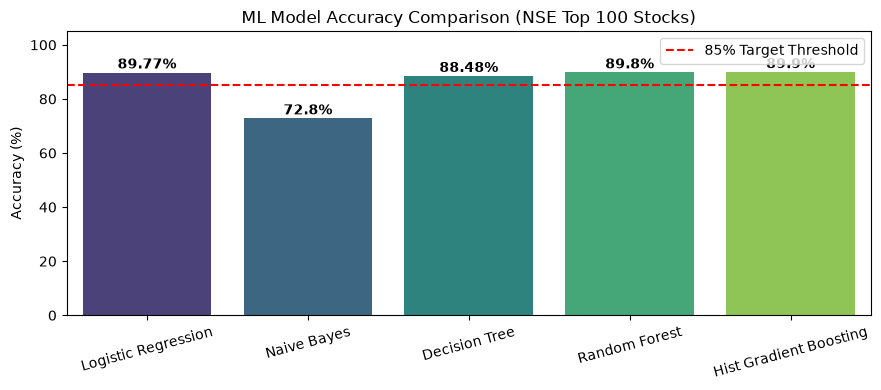

Best Model: Hist Gradient Boosting (89.9%)
Saved: best_stock_model.pkl, scaler.pkl, and model_metadata.json


In [9]:
import json
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Plot the accuracy comparison bar chart
plt.figure(figsize=(9, 4))
ax = sns.barplot(x=list(results.keys()), y=list(results.values()), palette="viridis")
plt.axhline(85, color='red', linestyle='--', label='85% Target Threshold')
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.title("ML Model Accuracy Comparison (NSE Top 100 Stocks)")
plt.xticks(rotation=15)
for i, v in enumerate(results.values()):
    ax.text(i, v + 1.5, f"{v}%", ha='center', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

# 2. Save the winning model and metadata for your FastAPI backend
best_name = max(results, key=results.get)
best_acc = results[best_name]
best_model, best_uses_scaled = trained_models[best_name]

joblib.dump(best_model, "best_stock_model.pkl")
joblib.dump(scaler, "scaler.pkl")
with open("model_metadata.json", "w") as f:
    json.dump({
        "model_name": best_name,
        "accuracy_pct": best_acc,
        "uses_scaled": best_uses_scaled,
        "features": features
    }, f, indent=2)

print(f"Best Model: {best_name} ({best_acc}%)")
print("Saved: best_stock_model.pkl, scaler.pkl, and model_metadata.json")